
# Klike Data Science Challenge
## Parte 1 — Análise Exploratória de Dados (EDA)

**Empresa:** Millai | Klike  
**Dataset:** `klike_challenge_dataset.csv`  
**Linguagem:** Python

---

### Contexto

O Klike é uma plataforma de análise de anúncios em vídeo que utiliza Inteligência Artificial para avaliar a qualidade dos criativos e identificar oportunidades de otimização de campanhas publicitárias.

Neste desafio, será analisado um dataset simulado contendo 500 registros de criativos de vídeo veiculados em diferentes plataformas digitais, incluindo Meta, TikTok e LinkedIn.

Cada registro reúne características do criativo, informações sobre a campanha e métricas de desempenho, como CTR, ROAS, conversões e o `klike_score`.

### Objetivo da análise

Esta etapa tem como objetivo compreender a estrutura e a qualidade dos dados, identificar padrões relevantes e investigar possíveis associações entre características dos criativos e desempenho das campanhas.

Os resultados servirão de base para as etapas posteriores de modelagem preditiva e construção de um sistema de recomendações.



### Metodologia da análise exploratória

A análise será conduzida em etapas:

1. **Inspeção inicial:** identificação das dimensões, tipos de dados e estrutura do dataset.
2. **Qualidade dos dados:** investigação de valores ausentes, duplicatas e inconsistências.
3. **Distribuições e outliers:** análise do comportamento das variáveis e identificação de valores extremos.
4. **Relações entre variáveis:** investigação de associações entre atributos dos criativos e métricas de performance.
5. **Análise por plataforma:** comparação dos padrões observados em Meta, TikTok e LinkedIn.
6. **Visualização e interpretação:** apresentação dos principais insights com foco em decisões de marketing.

As decisões de tratamento serão fundamentadas nas características observadas no dataset, evitando alterações que possam distorcer os resultados.



---

## 1. Preparação do ambiente e carregamento dos dados

Nesta seção, serão importadas as bibliotecas utilizadas na análise e carregado o dataset original.

A exploração será realizada inicialmente sobre os dados brutos, preservando os registros originais para permitir a comparação entre o estado inicial e eventuais transformações posteriores.


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Bibliotecas importadas com sucesso.")


Bibliotecas importadas com sucesso.


In [4]:

df_raw = pd.read_csv("klike_challenge_dataset.csv")

# Cópia de trabalho para preservar os dados originais
df = df_raw.copy()

print(f"Quantidade de registros: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

display(df.head())


Quantidade de registros: 500
Quantidade de colunas: 26


,campaign_id,date,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,has_cta,has_hook,has_face,text_density,music_voice_ratio,impressions,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
0,KLK-0001,2024-01-01,Meta,Branding,awareness,18-24,False,NaN,vertical,True,True,False,True,medium,0.39,150825,5882,0.0390,0.82,4823.24,48,0.00,0.00,3.9,0.0446,63.6
1,KLK-0002,2024-03-22,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,True,True,True,low,0.07,7433,493,0.0664,3.54,1745.22,34,NaN,0.16,6.4,0.0217,70.0
2,KLK-0003,2024-05-04,TikTok,SaaS,traffic,25-34,False,8.0,vertical,True,True,True,True,medium,0.43,193198,15069,0.0780,0.38,5726.22,492,51053.44,8.92,8.0,0.1000,99.1
3,KLK-0004,2024-12-27,TikTok,Lead Gen,engagement,25-34,False,27.0,quadrado,False,True,True,True,medium,0.54,6506,601,0.0925,0.71,426.71,19,1113.78,2.61,20.3,0.0414,74.9
4,KLK-0005,2024-07-10,Meta,Branding,engagement,25-34,False,34.0,vertical,True,True,True,True,low,0.35,63830,2355,0.0369,0.38,894.90,13,0.00,0.00,34.0,0.0184,77.9



---

## 2. Diagnóstico da qualidade dos dados

### 2.1. Identificação de valores ausentes

Valores ausentes (*missing values*) podem comprometer análises estatísticas, introduzir vieses e afetar o desempenho de modelos preditivos.

Antes de aplicar qualquer tratamento, será realizado um diagnóstico para identificar:

- A quantidade total de valores ausentes no dataset.
- O número de valores ausentes por coluna.
- O percentual de ausência de cada variável.
- A proporção de registros que apresentam pelo menos um valor ausente.

Nesta etapa, nenhum valor será removido ou substituído. O objetivo é quantificar o problema e reunir evidências para definir uma estratégia de tratamento adequada.


In [6]:

# Dimensões do dataset
n_linhas, n_colunas = df.shape
total_celulas = df.size

# Quantidade e percentual de valores ausentes por coluna
nulos_por_coluna = df.isna().sum()
percentual_nulos = (nulos_por_coluna / n_linhas) * 100

resumo_nulos = pd.DataFrame({
    "Tipo de dado": df.dtypes.astype(str),
    "Quantidade de nulos": nulos_por_coluna,
    "Percentual de nulos (%)": percentual_nulos.round(2)
})

# Ordenar pela quantidade de valores ausentes
resumo_nulos = resumo_nulos.sort_values(
    by="Quantidade de nulos",
    ascending=False
)

# Indicadores gerais
total_nulos = df.isna().sum().sum()
percentual_geral = (total_nulos / total_celulas) * 100
linhas_com_nulos = df.isna().any(axis=1).sum()

print("=== RESUMO GERAL ===")
print(f"Total de registros: {n_linhas}")
print(f"Total de variáveis: {n_colunas}")
print(f"Total de células: {total_celulas}")
print(f"Total de valores ausentes: {total_nulos}")
print(f"Percentual geral de ausência: {percentual_geral:.2f}%")
print(f"Registros com pelo menos um nulo: {linhas_com_nulos}")
print(f"Colunas com valores ausentes: {(nulos_por_coluna > 0).sum()}")

print("\n=== VALORES AUSENTES POR COLUNA ===")
display(
    resumo_nulos.style
    .format({"Percentual de nulos (%)": "{:.2f}%"})
    .background_gradient(
        subset=["Quantidade de nulos"],
        cmap="Oranges"
    )
)


=== RESUMO GERAL ===
Total de registros: 500
Total de variáveis: 26
Total de células: 13000
Total de valores ausentes: 235
Percentual geral de ausência: 1.81%
Registros com pelo menos um nulo: 191
Colunas com valores ausentes: 7

=== VALORES AUSENTES POR COLUNA ===


,Tipo de dado,Quantidade de nulos,Percentual de nulos (%)
has_subtitle,object,46,9.20%
video_duration_s,float64,39,7.80%
music_voice_ratio,float64,38,7.60%
engagement_rate,float64,32,6.40%
cpc,float64,28,5.60%
avg_watch_time_s,float64,27,5.40%
revenue,float64,25,5.00%
date,str,0,0.00%
platform,str,0,0.00%
campaign_id,str,0,0.00%



### 2.2. Distribuição dos valores ausentes por variável

Para complementar a análise quantitativa, será construído um gráfico de barras com o percentual de valores ausentes em cada variável.

Essa visualização permite identificar rapidamente quais atributos apresentam maior incompletude e ajuda a priorizar as próximas etapas do diagnóstico.

A presença de valores ausentes não implica, necessariamente, que os registros devam ser excluídos. A estratégia de tratamento dependerá da quantidade de ausências, do tipo de variável e dos possíveis mecanismos responsáveis pela ausência dos dados.


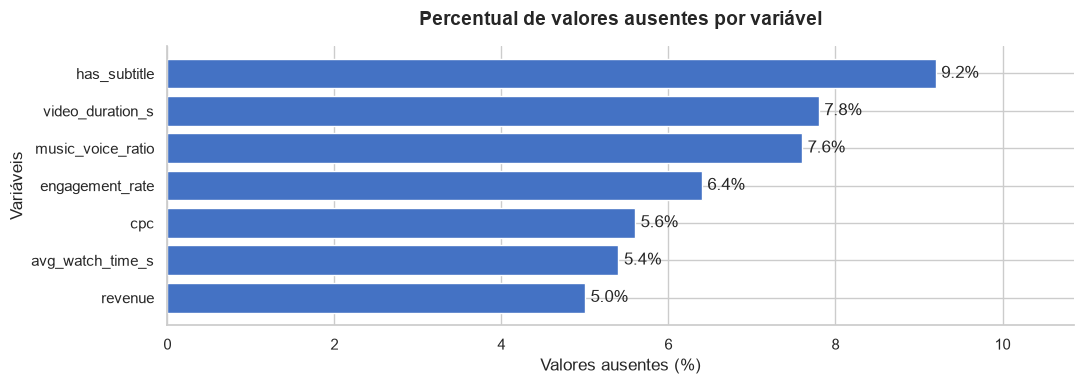

In [7]:

# Selecionar somente colunas com valores ausentes
nulos_grafico = (
    resumo_nulos[resumo_nulos["Quantidade de nulos"] > 0]
    .sort_values("Percentual de nulos (%)", ascending=True)
)

if nulos_grafico.empty:
    print("Nenhuma variável apresenta valores ausentes.")
else:
    fig, ax = plt.subplots(
        figsize=(11, max(4, len(nulos_grafico) * 0.45))
    )

    barras = ax.barh(
        nulos_grafico.index,
        nulos_grafico["Percentual de nulos (%)"],
        color="#4472C4"
    )

    ax.bar_label(barras, fmt="%.1f%%", padding=4)

    ax.set_title(
        "Percentual de valores ausentes por variável",
        fontsize=14,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel("Valores ausentes (%)")
    ax.set_ylabel("Variáveis")

    ax.set_xlim(
        0,
        max(nulos_grafico["Percentual de nulos (%)"]) * 1.18
    )

    sns.despine()
    plt.tight_layout()
    plt.show()



### 2.3. Interpretação e decisões de tratamento

A partir dos resultados anteriores, serão avaliados:

- **Magnitude das ausências:** quais variáveis apresentam maior percentual de dados faltantes?
- **Relevância das variáveis:** as colunas incompletas são importantes para analisar a performance ou prever o `klike_score`?
- **Possíveis mecanismos de ausência:** os valores faltantes apresentam padrões relacionados a outras variáveis?
- **Estratégia de tratamento:** é mais adequado preservar, imputar ou excluir os valores ausentes?

A decisão de tratamento será tomada após investigar os padrões de ausência, procurando minimizar a perda de informação e o risco de introdução de vieses.



### 2.4. Investigação dos padrões de ausência

A quantidade de valores ausentes, isoladamente, não permite determinar como esses dados devem ser tratados.

É necessário investigar se as ausências ocorrem de maneira isolada, se diferentes variáveis apresentam valores faltantes simultaneamente e se existem relações com características das campanhas.

Esta etapa busca identificar padrões que possam indicar mecanismos de ausência e orientar as decisões posteriores de tratamento.

Inicialmente, serão analisadas a distribuição de nulos por registro e a frequência dos padrões de ausência observados.


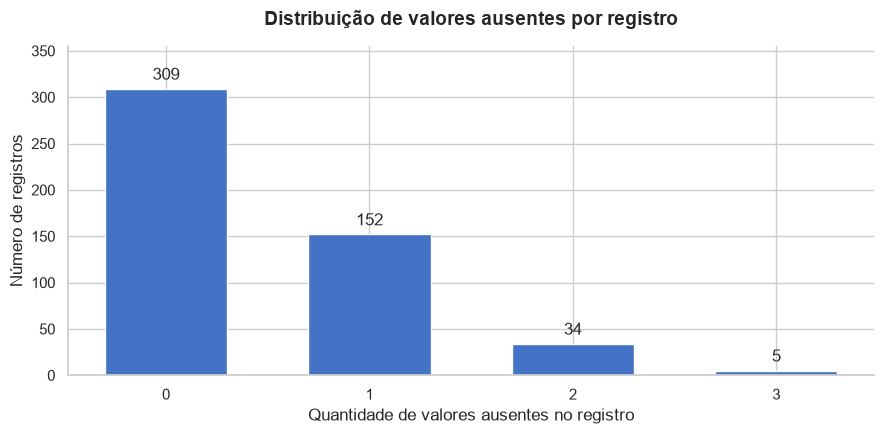

,Quantidade de nulos,Número de registros,Percentual (%)
0,0,309,61.8
1,1,152,30.4
2,2,34,6.8
3,3,5,1.0


In [8]:

# Quantidade de valores ausentes em cada registro
nulos_por_linha = df.isna().sum(axis=1)

distribuicao_nulos = (
    nulos_por_linha
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(9, 4.5))

barras = ax.bar(
    distribuicao_nulos.index.astype(str),
    distribuicao_nulos.values,
    color="#4472C4",
    width=0.6
)

ax.bar_label(barras, padding=4)

ax.set_title(
    "Distribuição de valores ausentes por registro",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Quantidade de valores ausentes no registro")
ax.set_ylabel("Número de registros")

ax.set_ylim(0, distribuicao_nulos.max() * 1.15)

sns.despine()
plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        "Quantidade de nulos": distribuicao_nulos.index,
        "Número de registros": distribuicao_nulos.values,
        "Percentual (%)": (
            distribuicao_nulos.values / len(df) * 100
        ).round(2)
    })
)



### 2.5. Visualização dos padrões de ausência

A matriz de ausência permite observar como os valores faltantes estão distribuídos ao longo dos registros e das variáveis incompletas.

Cada linha representa uma campanha e cada coluna corresponde a uma variável com dados ausentes.

Essa análise ajuda a identificar possíveis concentrações de ausências e a verificar visualmente se diferentes variáveis tendem a apresentar valores faltantes nos mesmos registros.


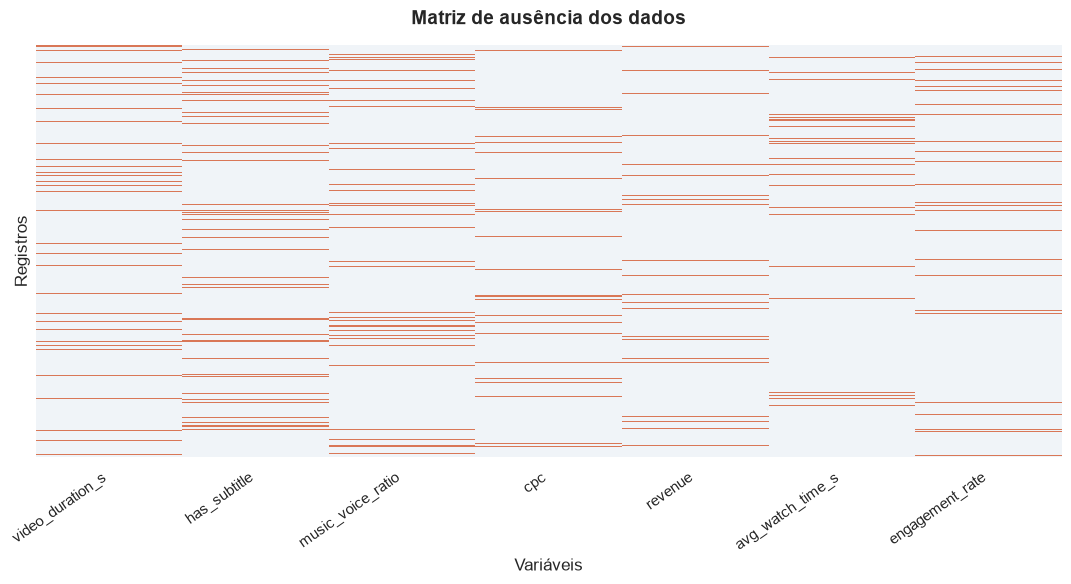

In [9]:

# Selecionar somente variáveis com valores ausentes
colunas_com_nulos = df.columns[df.isna().any()]

matriz_ausencia = (
    df[colunas_com_nulos]
    .isna()
    .astype(int)
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.heatmap(
    matriz_ausencia,
    cmap=["#F0F4F8", "#D97757"],
    cbar=False,
    yticklabels=False,
    linewidths=0,
    ax=ax
)

ax.set_title(
    "Matriz de ausência dos dados",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Variáveis")
ax.set_ylabel("Registros")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



### 2.6. Associação entre os indicadores de ausência

Além da inspeção visual, será avaliado se a ausência de uma variável está associada à ausência de outras.

Para isso, serão criados indicadores binários:

- **0:** valor presente.
- **1:** valor ausente.

A correlação entre esses indicadores será utilizada como ferramenta exploratória para investigar possíveis relações entre os padrões de ausência.

Correlações positivas indicam tendência de ausência conjunta, enquanto correlações negativas indicam que as ausências tendem a ocorrer separadamente.

Essa análise não determina, isoladamente, se os dados são MCAR, MAR ou MNAR.


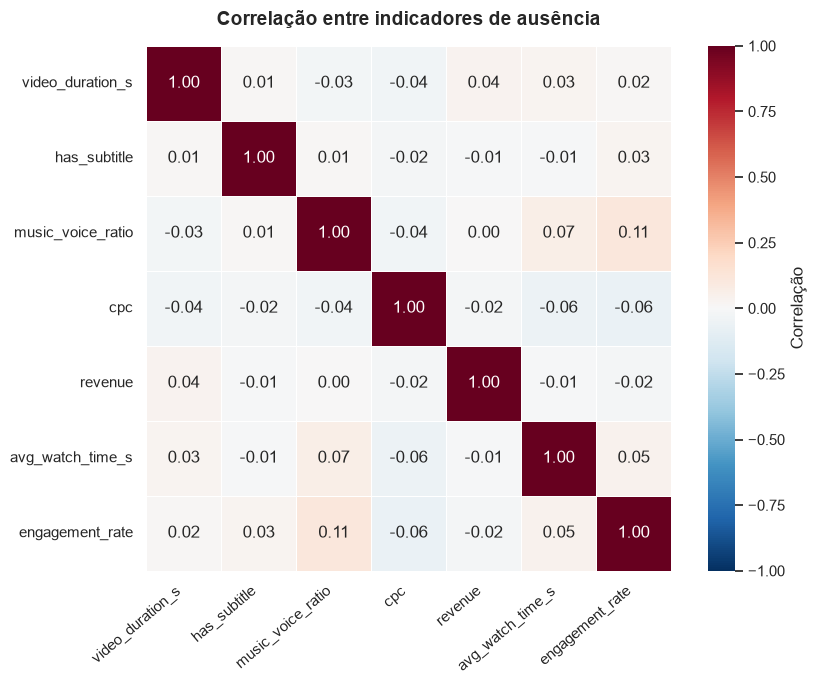

In [13]:

# Indicadores binários de ausência
indicadores_ausencia = df[colunas_com_nulos].isna().astype(int)

# Correlação entre indicadores
correlacao_ausencia = indicadores_ausencia.corr()

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    correlacao_ausencia,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlação"},
    ax=ax
)

ax.set_title(
    "Correlação entre indicadores de ausência",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



### 2.7. Ausências por plataforma e objetivo da campanha

Para investigar se os valores faltantes podem estar associados a características observáveis, serão comparadas as taxas de ausência entre diferentes plataformas e objetivos de campanha.

Essa análise é importante porque determinados dados podem ser registrados de maneira diferente dependendo da plataforma ou do tipo de campanha.

Serão analisadas as taxas de ausência condicionadas às variáveis `platform` e `objective`. Diferenças relevantes entre grupos poderão motivar investigações estatísticas adicionais.


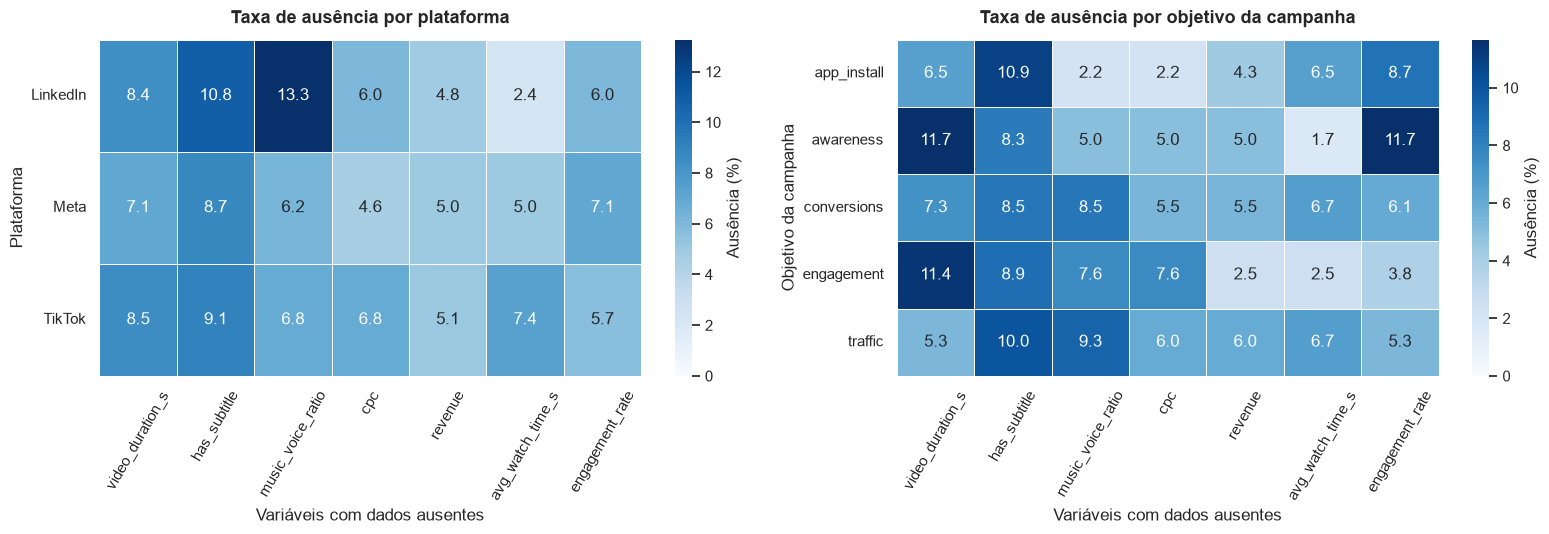

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

variaveis_grupo = {
    "platform": "Plataforma",
    "objective": "Objetivo da campanha"
}

for ax, (coluna, titulo) in zip(axes, variaveis_grupo.items()):

    taxas = (
        indicadores_ausencia
        .groupby(df[coluna])
        .mean()
        .mul(100)
    )

    sns.heatmap(
        taxas,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        cbar_kws={"label": "Ausência (%)"},
        linewidths=0.5,
        linecolor="white",
        ax=ax
    )

    ax.set_title(
        f"Taxa de ausência por {titulo.lower()}",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("Variáveis com dados ausentes")
    ax.set_ylabel(titulo)

    ax.tick_params(axis="x", rotation=60)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()



### 2.8. Hipóteses sobre os mecanismos de ausência

Os mecanismos de ausência podem ser classificados em três categorias:

| Mecanismo | Definição |
|---|---|
| **MCAR** (*Missing Completely At Random*) | A ausência não depende dos valores observados nem dos valores ausentes. |
| **MAR** (*Missing At Random*) | A ausência pode depender de variáveis observadas, mas não do próprio valor faltante após considerar essas variáveis. |
| **MNAR** (*Missing Not At Random*) | A ausência depende de informações não observadas, incluindo potencialmente o próprio valor ausente. |

As análises anteriores fornecem evidências exploratórias sobre possíveis associações entre ausências e variáveis observadas.


### 2.9. Conclusão do diagnóstico de valores ausentes

O dataset apresenta 235 valores ausentes, correspondentes a 1,81% das células. Entretanto, 38,2% dos registros possuem pelo menos um valor faltante.

A análise dos padrões de ausência não revelou associações fortes entre as variáveis incompletas ou diferenças sistemáticas evidentes por plataforma e objetivo da campanha.

Assim, **MCAR é uma hipótese plausível para a maioria das variáveis**, embora não seja possível descartar MAR ou MNAR apenas com as análises realizadas.

Considerando a baixa proporção geral de valores ausentes, será adotada uma abordagem conservadora:

- Preservar os registros originais durante a análise exploratória.
- Evitar a exclusão indiscriminada de linhas incompletas.
- Avaliar o tratamento de cada variável conforme sua natureza e relevância.
- Realizar a imputação necessária à modelagem dentro do pipeline de treinamento, evitando vazamento de informações.

Essa estratégia busca preservar a representatividade do dataset sem introduzir complexidade desnecessária.



---

## 3. Análise das distribuições e identificação de outliers

Nesta etapa, serão investigadas as distribuições das variáveis numéricas e a presença de valores extremos.

O objetivo é compreender o comportamento dos dados, identificar possíveis inconsistências e avaliar se determinados valores representam erros ou características legítimas das campanhas.

Serão analisadas especialmente as métricas de performance, como CTR, CPC, ROAS, conversões e `klike_score`.

**Critério de tratamento:** valores extremos não serão removidos automaticamente. Sua interpretação considerará a distribuição da variável, o contexto de negócio e o possível impacto nas análises posteriores.



### 3.1. Análise estatística das variáveis numéricas

Inicialmente, serão examinadas as principais estatísticas descritivas das variáveis numéricas, incluindo média, mediana, desvio padrão, quartis e valores extremos.

Essa análise permite identificar diferenças de escala, possíveis assimetrias e valores que merecem investigação.

Serão consideradas tanto as características dos vídeos quanto as métricas de desempenho das campanhas.

A interpretação levará em conta o contexto de negócio, uma vez que campanhas publicitárias podem apresentar diferenças significativas de investimento, alcance e resultados.


In [15]:

# Selecionar variáveis numéricas
colunas_numericas = df.select_dtypes(include="number").columns

# Estatísticas descritivas
estatisticas = (
    df[colunas_numericas]
    .describe()
    .T
    .rename(columns={
        "count": "Registros válidos",
        "mean": "Média",
        "std": "Desvio padrão",
        "min": "Mínimo",
        "25%": "Q1",
        "50%": "Mediana",
        "75%": "Q3",
        "max": "Máximo"
    })
)

display(
    estatisticas.style
    .format("{:,.2f}")
    .background_gradient(
        subset=["Média", "Mediana"],
        cmap="Blues"
    )
)


,Registros válidos,Média,Desvio padrão,Mínimo,Q1,Mediana,Q3,Máximo
video_duration_s,461.00,19.39,13.53,5.00,11.00,16.00,25.00,115.00
music_voice_ratio,462.00,0.40,0.20,0.02,0.23,0.39,0.55,0.92
impressions,500.00,"153,738.52","1,171,735.61","1,000.00","9,986.00","23,241.00","55,172.75","14,052,761.00"
clicks,500.00,"3,594.10","7,018.21",4.00,461.75,"1,351.00","3,583.25","72,545.00"
ctr,500.00,0.07,0.05,0.00,0.03,0.06,0.10,0.15
cpc,472.00,1.11,1.96,0.05,0.53,0.71,1.02,26.05
spend,500.00,"4,213.15","11,573.98",2.96,313.45,"1,031.00","2,867.95","121,226.10"
conversions,500.00,131.35,314.57,0.00,10.00,34.50,111.00,"3,666.00"
revenue,475.00,"6,367.94","19,267.18",0.00,262.18,"1,201.05","4,189.02","241,597.29"
roas,500.00,2.50,3.59,0.00,0.43,1.49,3.25,39.92



### 3.2. Distribuição das principais métricas

Para compreender melhor o comportamento das campanhas, serão analisadas as distribuições de quatro variáveis:

- `klike_score`: qualidade do criativo avaliada pelo sistema Klike.
- `ctr`: proporção de impressões que resultaram em cliques.
- `roas`: retorno sobre o investimento em publicidade.
- `video_duration_s`: duração do criativo em segundos.

Essas variáveis foram selecionadas por representarem diferentes dimensões do problema: qualidade do criativo, capacidade de atrair cliques, retorno financeiro e características do vídeo.

Os histogramas serão utilizados para identificar concentração de valores, assimetrias e possíveis observações extremas.


A seleção das variáveis foi realizada com base em sua relevância para o problema de negócio e na representatividade de diferentes dimensões do dataset.

Optou-se por priorizar a variável-alvo (`klike_score`), duas métricas de desempenho (`ctr` e `roas`) e uma característica do criativo (`video_duration_s`).

As demais variáveis numéricas serão consideradas nas análises de associação e performance, evitando visualizações redundantes nesta etapa.


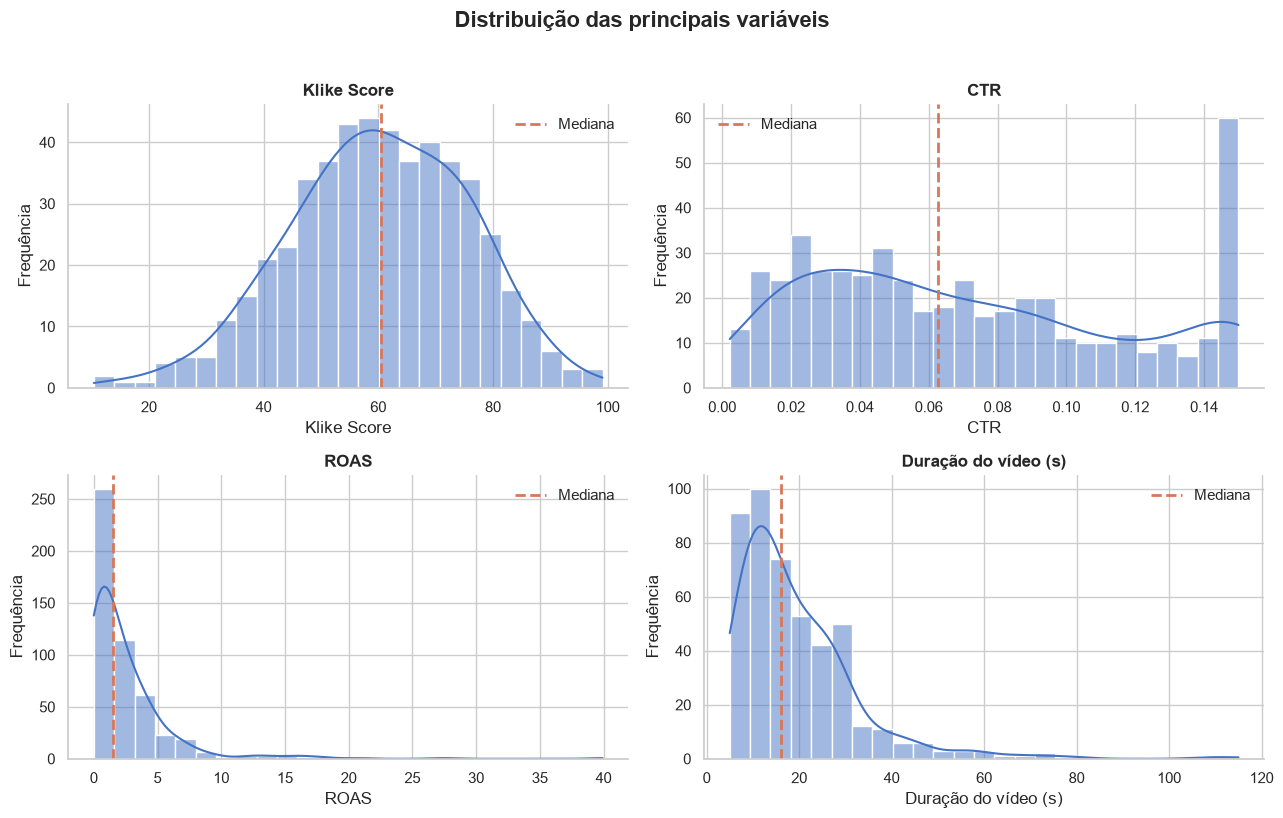

In [19]:

variaveis = {
    "klike_score": "Klike Score",
    "ctr": "CTR",
    "roas": "ROAS",
    "video_duration_s": "Duração do vídeo (s)"
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes = axes.flatten()

for ax, (coluna, titulo) in zip(axes, variaveis.items()):

    sns.histplot(
        data=df,
        x=coluna,
        bins=25,
        kde=True,
        color="#4472C4",
        edgecolor="white",
        ax=ax
    )

    ax.axvline(
        df[coluna].median(),
        color="#D97757",
        linestyle="--",
        linewidth=2,
        label="Mediana"
    )

    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel(titulo)
    ax.set_ylabel("Frequência")
    ax.legend(frameon=False)

fig.suptitle(
    "Distribuição das principais variáveis",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

sns.despine()
plt.tight_layout()
plt.show()



### 3.3. Identificação de valores extremos (outliers)

Valores extremos são observações que se distanciam significativamente do comportamento predominante de uma variável.

Em campanhas publicitárias, esses valores podem representar tanto inconsistências quanto situações legítimas, como anúncios com investimentos elevados, grande alcance ou retorno excepcional.

Para identificar potenciais outliers, será utilizado o método do intervalo interquartil (IQR):

$$
IQR = Q_3 - Q_1
$$

Serão considerados potenciais outliers os valores fora do intervalo:

$$
[Q_1 - 1{,}5 \times IQR,\; Q_3 + 1{,}5 \times IQR]
$$

Esse critério será utilizado apenas para sinalizar observações que merecem atenção, e não como justificativa automática para exclusão.


In [20]:

resultados_outliers = []

for coluna in colunas_numericas:

    serie = df[coluna].dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)

    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = (
        (serie < limite_inferior) |
        (serie > limite_superior)
    )

    resultados_outliers.append({
        "Variável": coluna,
        "Quantidade de outliers": outliers.sum(),
        "Percentual (%)": round(outliers.mean() * 100, 2)
    })

resumo_outliers = (
    pd.DataFrame(resultados_outliers)
    .sort_values("Percentual (%)", ascending=False)
    .reset_index(drop=True)
)

display(
    resumo_outliers.style
    .format({"Percentual (%)": "{:.2f}%"})
    .background_gradient(
        subset=["Quantidade de outliers"],
        cmap="Oranges"
    )
)


,Variável,Quantidade de outliers,Percentual (%)
0,cpc,66,13.98%
1,revenue,65,13.68%
2,spend,61,12.20%
3,conversions,61,12.20%
4,clicks,49,9.80%
5,impressions,45,9.00%
6,roas,27,5.40%
7,avg_watch_time_s,21,4.44%
8,engagement_rate,20,4.27%
9,video_duration_s,17,3.69%



### 3.4. Visualização dos valores extremos

Para complementar a identificação quantitativa, serão utilizados boxplots para examinar a dispersão e a presença de observações extremas.

A visualização será concentrada nas variáveis `cpc`, `roas`, `video_duration_s` e `klike_score`, permitindo comparar métricas financeiras, características do criativo e a variável-alvo.

Os resultados serão interpretados considerando que valores estatisticamente extremos não representam necessariamente erros nos dados.


Embora a identificação quantitativa de outliers tenha sido realizada para todas as variáveis numéricas elegíveis, a visualização foi limitada a quatro variáveis representativas.

A seleção contempla métricas financeiras (`cpc` e `roas`), características do criativo (`video_duration_s`) e a variável-alvo (`klike_score`).

Essa abordagem permite examinar diferentes tipos de valores extremos sem sobrecarregar a apresentação visual.


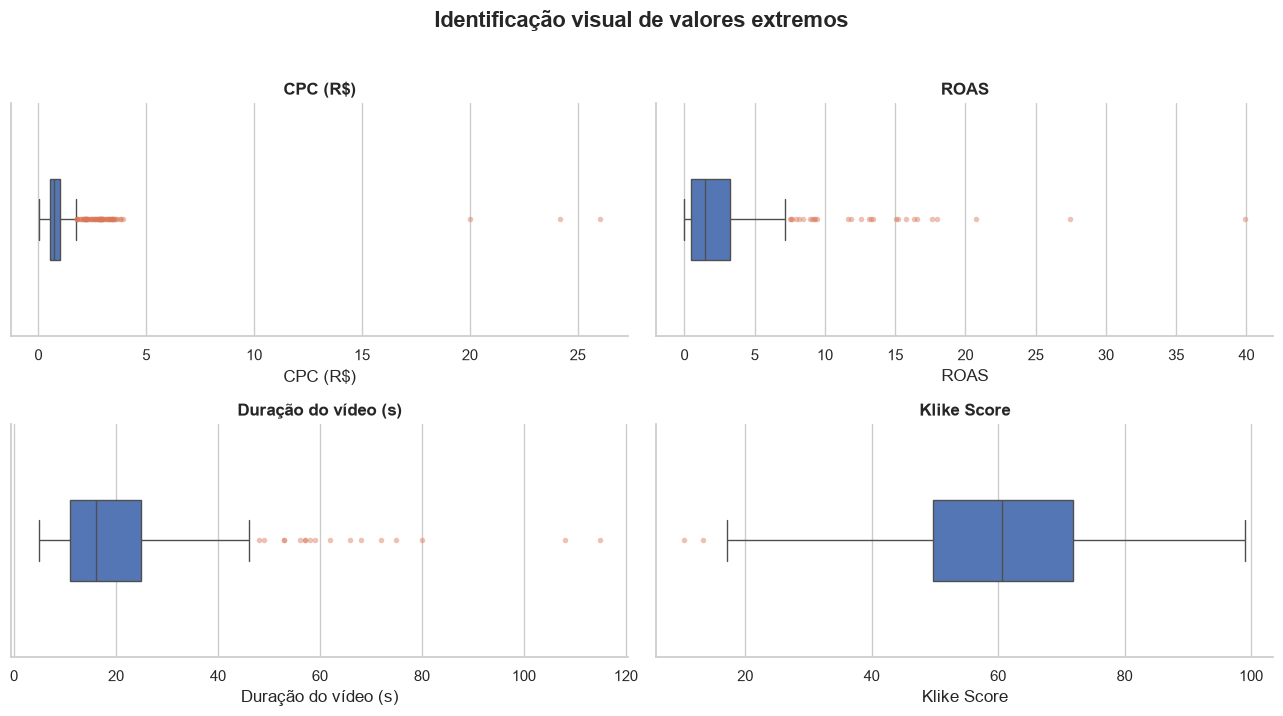

In [21]:

variaveis_boxplot = {
    "cpc": "CPC (R$)",
    "roas": "ROAS",
    "video_duration_s": "Duração do vídeo (s)",
    "klike_score": "Klike Score"
}

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
axes = axes.flatten()

for ax, (coluna, titulo) in zip(
    axes, variaveis_boxplot.items()
):

    sns.boxplot(
        x=df[coluna],
        color="#4472C4",
        width=0.35,
        flierprops={
            "marker": "o",
            "markersize": 4,
            "alpha": 0.45,
            "markerfacecolor": "#D97757",
            "markeredgecolor": "none"
        },
        ax=ax
    )

    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel(titulo)

fig.suptitle(
    "Identificação visual de valores extremos",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

sns.despine()
plt.tight_layout()
plt.show()



### 3.5. Considerações sobre valores extremos

A identificação estatística de outliers não implica necessariamente a presença de erros.

No contexto de campanhas publicitárias, métricas como impressões, investimento, conversões e ROAS podem apresentar distribuições assimétricas devido às diferenças de orçamento, público-alvo e desempenho dos anúncios.

Por esse motivo, será adotada uma abordagem conservadora:

- Preservar inicialmente os valores extremos.
- Investigar possíveis inconsistências e valores fora dos limites esperados.
- Considerar transformações ou métodos robustos caso os outliers prejudiquem a modelagem.

A remoção ou modificação de observações será realizada somente quando houver justificativa técnica ou evidência de inconsistência.



---

## 4. Verificação da consistência dos dados

Além da identificação de valores ausentes e outliers, é importante verificar a consistência lógica e matemática das informações presentes no dataset.

Algumas métricas de performance possuem relações matemáticas conhecidas:

- **CTR:** razão entre cliques e impressões.
- **CPC:** custo total dividido pelo número de cliques.
- **ROAS:** receita gerada dividida pelo investimento publicitário.

Nesta etapa, serão investigadas possíveis divergências entre os valores registrados e os valores calculados, considerando tolerâncias para arredondamentos.

Também serão verificadas duplicatas e possíveis violações de limites esperados. O objetivo é identificar inconsistências relevantes sem realizar alterações automáticas nos dados originais.


In [22]:

# Verificação de duplicatas
duplicatas = df.duplicated().sum()
ids_duplicados = df["campaign_id"].duplicated().sum()

# Verificação de limites esperados
verificacoes = {
    "Registros duplicados": duplicatas,
    "IDs duplicados": ids_duplicados,
    "CTR fora do intervalo [0, 1]": (
        ~df["ctr"].between(0, 1)
    ).sum(),
    "Klike Score fora do intervalo [0, 100]": (
        ~df["klike_score"].between(0, 100)
    ).sum(),
    "ROAS negativo": (df["roas"] < 0).sum(),
    "Impressões não positivas": (
        df["impressions"] <= 0
    ).sum(),
    "Cliques negativos": (df["clicks"] < 0).sum(),
    "Conversões negativas": (
        df["conversions"] < 0
    ).sum(),
    "Investimento não positivo": (
        df["spend"] <= 0
    ).sum()
}

resumo_verificacoes = pd.DataFrame(
    verificacoes.items(),
    columns=["Verificação", "Ocorrências"]
)

display(
    resumo_verificacoes.style
    .hide(axis="index")
    .background_gradient(
        subset=["Ocorrências"],
        cmap="Oranges"
    )
)


Verificação,Ocorrências
Registros duplicados,0
IDs duplicados,0
"CTR fora do intervalo [0, 1]",0
"Klike Score fora do intervalo [0, 100]",0
ROAS negativo,0
Impressões não positivas,0
Cliques negativos,0
Conversões negativas,0
Investimento não positivo,0



### 4.1. Consistência das métricas de performance

Para verificar a consistência das métricas, serão recalculados CTR, CPC e ROAS a partir de suas variáveis de origem:

$$
CTR = \frac{Clicks}{Impressions}
$$

$$
CPC = \frac{Spend}{Clicks}
$$

$$
ROAS = \frac{Revenue}{Spend}
$$

Os resultados serão comparados aos valores registrados no dataset.

Serão utilizadas tolerâncias para evitar que pequenas diferenças de arredondamento sejam classificadas como inconsistências. Divergências superiores a essas tolerâncias serão sinalizadas para investigação, sem correção automática.


In [23]:

# Recalcular métricas a partir dos dados disponíveis
metricas_calculadas = pd.DataFrame(index=df.index)

metricas_calculadas["ctr_calculado"] = (
    df["clicks"] / df["impressions"].replace(0, np.nan)
)

metricas_calculadas["cpc_calculado"] = (
    df["spend"] / df["clicks"].replace(0, np.nan)
)

metricas_calculadas["roas_calculado"] = (
    df["revenue"] / df["spend"].replace(0, np.nan)
)

# Tolerâncias para divergências
tolerancias = {
    "ctr": 0.0001,
    "cpc": 0.02,
    "roas": 0.02
}

resultados_consistencia = []

for metrica, tolerancia in tolerancias.items():

    calculado = metricas_calculadas[f"{metrica}_calculado"]
    registrado = df[metrica]

    diferenca = (registrado - calculado).abs()

    comparaveis = registrado.notna() & calculado.notna()
    inconsistentes = comparaveis & (diferenca > tolerancia)

    resultados_consistencia.append({
        "Métrica": metrica.upper(),
        "Registros comparáveis": comparaveis.sum(),
        "Divergências": inconsistentes.sum(),
        "Divergências (%)": (
            inconsistentes.sum() / comparaveis.sum() * 100
            if comparaveis.sum() else np.nan
        ),
        "Diferença máxima": diferenca.max()
    })

resumo_consistencia = pd.DataFrame(resultados_consistencia)

display(
    resumo_consistencia.style
    .hide(axis="index")
    .format({
        "Divergências (%)": "{:.2f}%",
        "Diferença máxima": "{:.4f}"
    })
    .background_gradient(
        subset=["Divergências"],
        cmap="Oranges"
    )
)


Métrica,Registros comparáveis,Divergências,Divergências (%),Diferença máxima
CTR,500,59,11.80%,0.0423
CPC,472,6,1.27%,4790.3145
ROAS,475,2,0.42%,13.4492



### 4.2. Interpretação das inconsistências

A comparação entre as métricas registradas e recalculadas permite identificar possíveis divergências nos dados.

É importante destacar que uma divergência matemática não indica, necessariamente, qual coluna está incorreta. Diferenças podem decorrer de arredondamentos, erros de registro ou particularidades na definição das métricas.

Por esse motivo, os valores originais serão preservados e as inconsistências serão sinalizadas.

Na etapa de modelagem, será avaliada a necessidade de correção ou exclusão pontual de observações inconsistentes, considerando o impacto dessas decisões sobre os resultados.

Essa abordagem prioriza a rastreabilidade e evita modificações sem justificativa.


In [24]:

registros_divergentes = []

for metrica, tolerancia in tolerancias.items():

    calculado = metricas_calculadas[f"{metrica}_calculado"]

    mascara = (
        df[metrica].notna()
        & calculado.notna()
        & ((df[metrica] - calculado).abs() > tolerancia)
    )

    encontrados = pd.DataFrame({
        "campaign_id": df.loc[mascara, "campaign_id"],
        "Métrica": metrica.upper(),
        "Valor registrado": df.loc[mascara, metrica],
        "Valor calculado": calculado.loc[mascara]
    })

    encontrados["Diferença absoluta"] = (
        encontrados["Valor registrado"]
        - encontrados["Valor calculado"]
    ).abs()

    registros_divergentes.append(encontrados)

divergencias = pd.concat(
    registros_divergentes,
    ignore_index=True
)

divergencias = divergencias.sort_values(
    "Diferença absoluta",
    ascending=False
)

print(f"Total de divergências identificadas: {len(divergencias)}")

display(
    divergencias.head(10).style
    .hide(axis="index")
    .format({
        "Valor registrado": "{:.4f}",
        "Valor calculado": "{:.4f}",
        "Diferença absoluta": "{:.4f}"
    })
)


Total de divergências identificadas: 67


campaign_id,Métrica,Valor registrado,Valor calculado,Diferença absoluta
KLK-0259,CPC,0.2700,4790.5845,4790.3145
KLK-0109,CPC,1.1800,246.5599,245.3799
KLK-0416,CPC,26.0500,0.7400,25.3100
KLK-0240,CPC,24.1700,0.9800,23.1900
KLK-0100,CPC,20.0000,0.3900,19.6100
KLK-0259,ROAS,13.4500,0.0008,13.4492
KLK-0224,CPC,1.2200,4.8118,3.5918
KLK-0109,ROAS,0.2600,0.0013,0.2587
KLK-0258,CTR,0.0426,0.0003,0.0423
KLK-0413,CTR,0.0374,0.0002,0.0372



### 4.3. Conclusão da análise de consistência

A verificação não identificou registros duplicados, identificadores repetidos ou violações dos limites básicos analisados.

Entretanto, foram encontradas divergências entre algumas métricas registradas e seus valores recalculados:

- **CTR:** 59 divergências em 500 registros comparáveis (11,80%).
- **CPC:** 6 divergências em 472 registros comparáveis (1,27%).
- **ROAS:** 2 divergências em 475 registros comparáveis (0,42%).

Algumas diferenças são expressivas e não podem ser atribuídas exclusivamente a arredondamentos.

**Decisão de tratamento:** os valores originais serão preservados. Para as análises de associação com métricas de performance, serão consideradas apenas observações com valores disponíveis e matematicamente consistentes para a métrica analisada.

Essa filtragem será aplicada individualmente a cada métrica, evitando a exclusão desnecessária de campanhas das demais análises.

Como as divergências podem não ser aleatórias, essa decisão será considerada uma limitação na interpretação dos resultados.



---

## 5. Relação entre características dos criativos e performance

Esta etapa busca identificar associações entre os atributos dos anúncios em vídeo e seus resultados de desempenho.

Serão investigadas características que podem ser modificadas durante a produção dos criativos, como presença de hook, CTA, legendas e rostos humanos.

A análise será realizada inicialmente de forma agregada e, posteriormente, segmentada por plataforma, considerando que diferentes ambientes publicitários podem apresentar comportamentos distintos.

### 5.1. Impacto associado aos atributos binários

A primeira comparação avaliará as diferenças de performance entre anúncios que apresentam ou não determinadas características.

Serão consideradas as seguintes métricas:

- **CTR:** capacidade de gerar cliques.
- **ROAS:** retorno sobre o investimento publicitário.
- **Engagement Rate:** proporção de interações.
- **Klike Score:** pontuação de qualidade atribuída ao criativo.

As diferenças identificadas representam associações observacionais e não devem ser interpretadas automaticamente como efeitos causais.


In [25]:

# Preservar o dataset de trabalho
df_performance = df.copy()

# Sinalizar valores matematicamente inconsistentes
for metrica, tolerancia in tolerancias.items():

    calculado = metricas_calculadas[f"{metrica}_calculado"]

    inconsistente = (
        df[metrica].notna()
        & calculado.notna()
        & ((df[metrica] - calculado).abs() > tolerancia)
    )

    # Desconsiderar somente a métrica afetada
    df_performance.loc[inconsistente, metrica] = np.nan

# Características e métricas selecionadas
atributos = [
    "has_hook",
    "has_cta",
    "has_subtitle",
    "has_face"
]

metricas = [
    "ctr",
    "roas",
    "engagement_rate",
    "klike_score"
]

print("Dataset preparado para análise de performance.")

display(
    pd.DataFrame({
        "Métrica": metricas,
        "Registros disponíveis": [
            df_performance[m].notna().sum()
            for m in metricas
        ]
    }).style.hide(axis="index")
)


Dataset preparado para análise de performance.


Métrica,Registros disponíveis
ctr,441
roas,498
engagement_rate,468
klike_score,500



### 5.2. Comparação de performance com e sem atributos criativos

Para cada atributo binário, serão comparadas as médias de desempenho entre campanhas que apresentam ou não a característica.

Além da diferença absoluta, será calculada a variação percentual em relação ao grupo sem o atributo.

A quantidade de observações válidas também será apresentada, permitindo avaliar o tamanho dos grupos comparados.

Os resultados serão utilizados para identificar possíveis oportunidades de melhoria, que posteriormente deverão ser investigadas considerando plataforma, objetivo e demais características das campanhas.


In [26]:

resultados = []

for atributo in atributos:
    for metrica in metricas:

        resumo = (
            df_performance
            .groupby(atributo)[metrica]
            .agg(["mean", "count"])
        )

        if not {False, True}.issubset(resumo.index):
            continue

        media_sem = resumo.loc[False, "mean"]
        media_com = resumo.loc[True, "mean"]

        diferenca = media_com - media_sem

        variacao_pct = (
            diferenca / abs(media_sem) * 100
            if pd.notna(media_sem) and media_sem != 0
            else np.nan
        )

        resultados.append({
            "Atributo": atributo,
            "Métrica": metrica,
            "N (sem)": int(resumo.loc[False, "count"]),
            "N (com)": int(resumo.loc[True, "count"]),
            "Média (sem)": media_sem,
            "Média (com)": media_com,
            "Diferença": diferenca,
            "Variação (%)": variacao_pct
        })

comparacao_atributos = pd.DataFrame(resultados)

display(
    comparacao_atributos.style
    .hide(axis="index")
    .format({
        "Média (sem)": "{:.4f}",
        "Média (com)": "{:.4f}",
        "Diferença": "{:+.4f}",
        "Variação (%)": "{:+.2f}%"
    })
    .background_gradient(
        subset=["Variação (%)"],
        cmap="RdYlGn",
        vmin=-50,
        vmax=50
    )
)


Atributo,Métrica,N (sem),N (com),Média (sem),Média (com),Diferença,Variação (%)
has_hook,ctr,214,227,0.0610,0.0845,+0.0236,+38.66%
has_hook,roas,242,256,2.5549,2.4121,-0.1428,-5.59%
has_hook,engagement_rate,224,244,0.0253,0.0304,+0.0051,+20.27%
has_hook,klike_score,244,256,51.3865,68.5160,+17.1295,+33.33%
has_cta,ctr,136,305,0.0702,0.0744,+0.0042,+5.99%
has_cta,roas,152,346,2.4611,2.4905,+0.0293,+1.19%
has_cta,engagement_rate,144,324,0.0291,0.0274,-0.0017,-5.86%
has_cta,klike_score,153,347,54.5699,62.6202,+8.0502,+14.75%
has_subtitle,ctr,169,230,0.0675,0.0784,+0.0109,+16.13%
has_subtitle,roas,191,261,2.4807,2.6290,+0.1484,+5.98%



### 5.3. Visualização das diferenças de performance

Para facilitar a interpretação dos resultados, será utilizado um mapa de calor com a variação percentual média associada à presença de cada atributo criativo.

Valores positivos indicam médias superiores nos anúncios com a característica, enquanto valores negativos indicam médias inferiores.

A visualização permite comparar diferentes métricas simultaneamente e identificar quais atributos merecem investigação mais aprofundada.

Como as diferenças são calculadas a partir de médias observacionais, os resultados não representam estimativas causais de impacto.


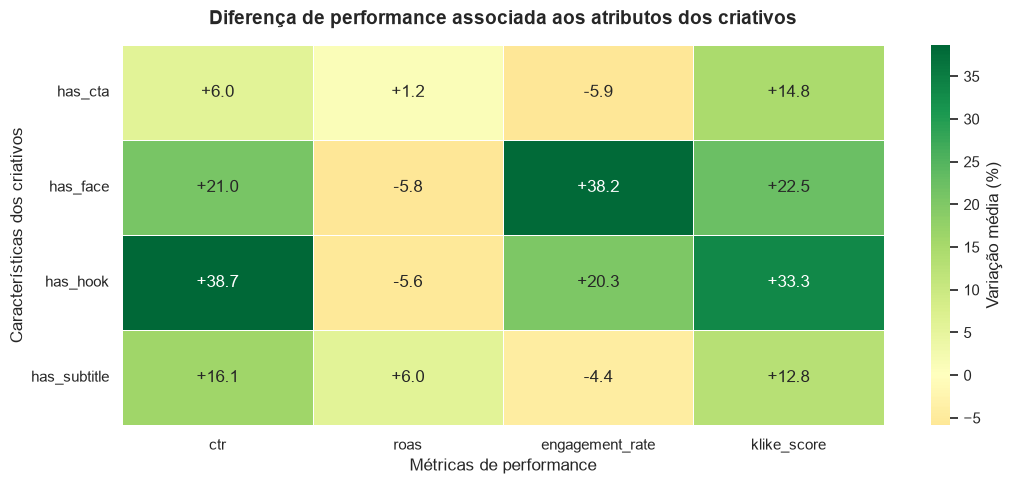

In [27]:

# Organizar dados para visualização
heatmap_performance = comparacao_atributos.pivot(
    index="Atributo",
    columns="Métrica",
    values="Variação (%)"
)

# Ordenar métricas
heatmap_performance = heatmap_performance[metricas]

fig, ax = plt.subplots(figsize=(11, 5))

sns.heatmap(
    heatmap_performance,
    annot=True,
    fmt="+.1f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Variação média (%)"},
    ax=ax
)

ax.set_title(
    "Diferença de performance associada aos atributos dos criativos",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Métricas de performance")
ax.set_ylabel("Características dos criativos")

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()



### 5.4. Principais insights da análise agregada

A comparação entre campanhas com e sem determinados atributos criativos revelou associações relevantes:

- **Hook:** associado a CTR médio 38,66% superior e Klike Score 33,33% maior.
- **Rosto humano:** associado a aumento de 38,21% na taxa média de engajamento.
- **CTA:** associado a Klike Score 14,75% maior, mas com diferença relativamente pequena no CTR (+5,99%).
- **Legendas:** associadas a CTR 16,13% superior e Klike Score 12,76% maior.

Os resultados sugerem que elementos capazes de capturar a atenção do espectador podem estar relacionados a melhores indicadores de desempenho.

Entretanto, as associações são agregadas e não estabelecem causalidade. Diferenças de plataforma, objetivo da campanha e público-alvo podem influenciar os resultados.

Por isso, a próxima etapa investigará se esses padrões permanecem consistentes entre as diferentes plataformas.



### 5.5. Análise de performance por plataforma

Os resultados agregados podem ocultar diferenças importantes entre plataformas, que possuem formatos, públicos e padrões de consumo distintos.

Para investigar essas diferenças, serão comparadas as associações entre atributos criativos e performance no Meta, TikTok e LinkedIn.

A análise será concentrada inicialmente em duas métricas:

- **CTR:** indicador de capacidade de gerar cliques.
- **Klike Score:** variável-alvo do desafio.

As comparações serão realizadas dentro de cada plataforma, considerando as diferenças percentuais entre campanhas com e sem cada atributo.

Para reduzir interpretações baseadas em amostras muito pequenas, serão apresentadas apenas comparações com pelo menos 10 observações válidas em cada grupo.


In [28]:

resultados_plataforma = []

for plataforma, grupo in df_performance.groupby("platform"):
    for atributo in atributos:
        for metrica in ["ctr", "klike_score"]:

            resumo = (
                grupo.groupby(atributo)[metrica]
                .agg(["mean", "count"])
            )

            if not {False, True}.issubset(resumo.index):
                continue

            n_sem = int(resumo.loc[False, "count"])
            n_com = int(resumo.loc[True, "count"])

            if min(n_sem, n_com) < 10:
                continue

            media_sem = resumo.loc[False, "mean"]
            media_com = resumo.loc[True, "mean"]

            variacao = (
                (media_com - media_sem) / abs(media_sem) * 100
                if pd.notna(media_sem) and media_sem != 0
                else np.nan
            )

            resultados_plataforma.append({
                "Plataforma": plataforma,
                "Atributo": atributo,
                "Métrica": metrica,
                "N (sem)": n_sem,
                "N (com)": n_com,
                "Variação (%)": variacao
            })

comparacao_plataformas = pd.DataFrame(resultados_plataforma)

display(
    comparacao_plataformas.style
    .hide(axis="index")
    .format({"Variação (%)": "{:+.2f}%"})
    .background_gradient(
        subset=["Variação (%)"],
        cmap="RdYlGn",
        vmin=-50,
        vmax=50
    )
)


Plataforma,Atributo,Métrica,N (sem),N (com),Variação (%)
LinkedIn,has_hook,ctr,31,41,+49.68%
LinkedIn,has_hook,klike_score,38,45,+33.46%
LinkedIn,has_cta,ctr,19,53,+10.53%
LinkedIn,has_cta,klike_score,22,61,+17.59%
LinkedIn,has_subtitle,ctr,25,38,+3.04%
LinkedIn,has_subtitle,klike_score,29,45,+9.90%
LinkedIn,has_face,ctr,30,42,+26.81%
LinkedIn,has_face,klike_score,35,48,+26.90%
Meta,has_hook,ctr,100,114,+34.29%
Meta,has_hook,klike_score,113,128,+35.09%



### 5.6. Comparação visual das associações por plataforma

Para facilitar a identificação de padrões específicos, serão construídos dois mapas de calor, um para CTR e outro para Klike Score.

As linhas representam as plataformas, enquanto as colunas representam os atributos criativos.

Os valores indicam a diferença percentual média associada à presença de cada característica dentro da respectiva plataforma.

Diferenças de sinal ou magnitude entre plataformas podem indicar a necessidade de recomendações contextualizadas, em vez de aplicar uma única regra para todas as campanhas.


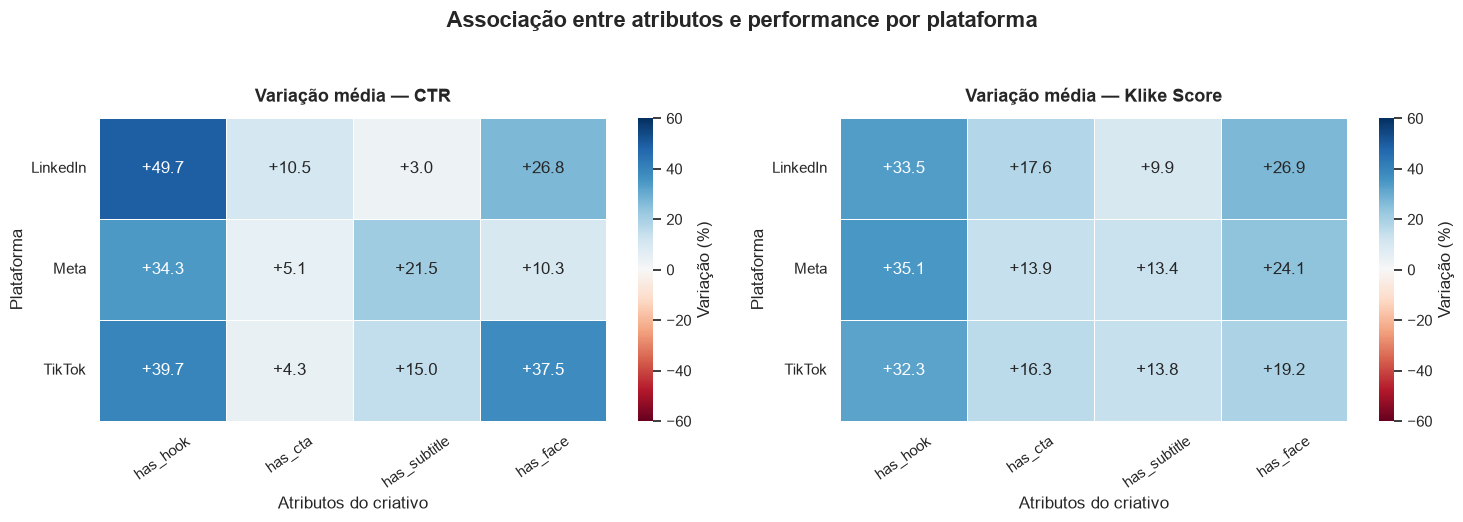

In [29]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

titulos = {
    "ctr": "CTR",
    "klike_score": "Klike Score"
}

for ax, (metrica, titulo) in zip(axes, titulos.items()):

    dados = comparacao_plataformas[
        comparacao_plataformas["Métrica"] == metrica
    ]

    matriz = dados.pivot(
        index="Plataforma",
        columns="Atributo",
        values="Variação (%)"
    ).reindex(columns=atributos)

    sns.heatmap(
        matriz,
        annot=True,
        fmt="+.1f",
        cmap="RdBu",
        center=0,
        vmin=-60,
        vmax=60,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Variação (%)"},
        ax=ax
    )

    ax.set_title(
        f"Variação média — {titulo}",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("Atributos do criativo")
    ax.set_ylabel("Plataforma")
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Associação entre atributos e performance por plataforma",
    fontsize=16,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()



### 5.7. Principais insights por plataforma

A análise segmentada revelou que algumas características dos criativos apresentam associações positivas consistentes, enquanto outras variam entre plataformas.

**Principais resultados:**

- **Hook:** associação positiva com CTR e Klike Score em todas as plataformas, destacando-se como o atributo mais consistente da análise.
- **Rosto humano:** associação especialmente elevada com CTR no TikTok (+37,51%), sugerindo maior relevância nessa plataforma.
- **Legendas:** associação mais expressiva com CTR no Meta (+21,52%), enquanto no LinkedIn a diferença foi relativamente pequena (+3,04%).
- **CTA:** associação positiva com Klike Score nas três plataformas, mas diferenças mais moderadas no CTR.

Esses resultados reforçam a importância de considerar a plataforma na construção do sistema de recomendações.

Entretanto, as diferenças observadas não estabelecem relações causais e podem ser influenciadas por outras características das campanhas, como público-alvo, categoria e objetivo publicitário.



### 5.8. Relação entre características numéricas e performance

Além dos atributos binários, características quantitativas dos vídeos podem apresentar associações relevantes com o desempenho das campanhas.

Serão investigadas duas variáveis:

- **Duração do vídeo (`video_duration_s`):** permite avaliar se vídeos mais curtos ou mais longos apresentam diferenças de performance.
- **Proporção música/voz (`music_voice_ratio`):** representa o equilíbrio entre música e narração, variando de 0 (somente voz) a 1 (somente música).

A análise será realizada por plataforma, utilizando agrupamentos para facilitar a interpretação e reduzir a influência de observações individuais.

Serão comparadas as médias de CTR e Klike Score, preservando apenas os registros com informações disponíveis e consistentes para cada métrica.

Os resultados serão utilizados para identificar tendências e possíveis oportunidades de otimização dos criativos.


In [30]:

df_duracao = df_performance.copy()

# Definir faixas de duração
bins = [0, 15, 30, 60, np.inf]
labels = ["Até 15s", "16–30s", "31–60s", "Acima de 60s"]

df_duracao["faixa_duracao"] = pd.cut(
    df_duracao["video_duration_s"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Resumo por plataforma e faixa de duração
resumo_duracao = (
    df_duracao
    .groupby(
        ["platform", "faixa_duracao"],
        observed=True
    )
    .agg(
        ctr_medio=("ctr", "mean"),
        n_ctr=("ctr", "count"),
        score_medio=("klike_score", "mean"),
        n_score=("klike_score", "count")
    )
    .reset_index()
)

display(
    resumo_duracao.style
    .hide(axis="index")
    .format({
        "ctr_medio": "{:.4f}",
        "score_medio": "{:.2f}"
    })
)


platform,faixa_duracao,ctr_medio,n_ctr,score_medio,n_score
LinkedIn,Até 15s,0.0807,12,53.10,13
LinkedIn,16–30s,0.0742,40,58.08,44
LinkedIn,31–60s,0.0615,12,51.60,16
LinkedIn,Acima de 60s,0.0875,3,66.10,3
Meta,Até 15s,0.0818,91,61.30,105
Meta,16–30s,0.0698,81,58.57,87
Meta,31–60s,0.0604,23,61.01,27
Meta,Acima de 60s,0.0523,5,66.10,5
TikTok,Até 15s,0.0636,99,60.27,110
TikTok,16–30s,0.0862,41,63.60,46


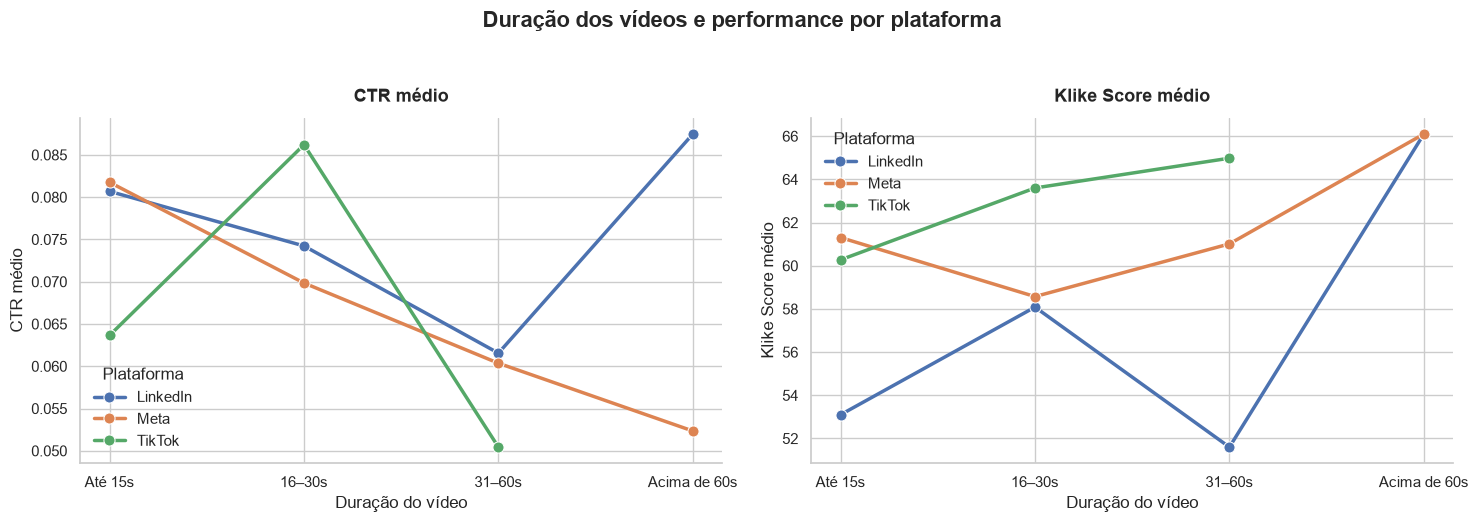

In [31]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

metricas_duracao = {
    "ctr_medio": "CTR médio",
    "score_medio": "Klike Score médio"
}

for ax, (metrica, titulo) in zip(
    axes, metricas_duracao.items()
):

    sns.lineplot(
        data=resumo_duracao,
        x="faixa_duracao",
        y=metrica,
        hue="platform",
        marker="o",
        linewidth=2.5,
        markersize=8,
        sort=False,
        ax=ax
    )

    ax.set_title(
        titulo,
        fontsize=13,
        fontweight="bold",
        pad=12
    )
    ax.set_xlabel("Duração do vídeo")
    ax.set_ylabel(titulo)
    ax.legend(title="Plataforma", frameon=False)

fig.suptitle(
    "Duração dos vídeos e performance por plataforma",
    fontsize=16,
    fontweight="bold",
    y=1.04
)

sns.despine()
plt.tight_layout()
plt.show()



### 5.9. Principais insights sobre a duração dos vídeos

A análise revelou diferenças na relação entre duração e performance nas três plataformas.

- **Meta:** vídeos de até 15 segundos apresentaram maior CTR médio (8,18%), com redução progressiva nas faixas de duração superiores.
- **TikTok:** vídeos de 16 a 30 segundos apresentaram o maior CTR médio (8,62%), superando os vídeos de até 15 segundos (6,36%).
- **LinkedIn:** vídeos de até 15 segundos apresentaram CTR médio de 8,07%, superior às faixas intermediárias.

Embora algumas faixas mais longas apresentem resultados elevados, elas possuem poucas observações, tornando suas médias menos confiáveis.

Os resultados sugerem que a duração mais favorável pode variar conforme a plataforma, reforçando a necessidade de recomendações contextualizadas.

**Limitação:** as diferenças observadas são descritivas e podem ser influenciadas por outros atributos dos criativos e características das campanhas.



### 5.10. Relação entre música/voz e performance

A proporção entre música e voz pode influenciar a experiência do espectador e sua interação com o anúncio.

Para investigar essa relação, será calculada a correlação de Spearman entre `music_voice_ratio` e as métricas CTR e Klike Score, separadamente por plataforma.

Essa abordagem permite identificar possíveis tendências monotônicas, sem pressupor uma relação linear.

Os resultados serão interpretados de forma exploratória, considerando a magnitude e a direção das correlações.


In [33]:

resultados_musica = []

for plataforma, grupo in df_performance.groupby("platform"):

    for metrica in ["ctr", "klike_score"]:

        dados = grupo[
            ["music_voice_ratio", metrica]
        ].dropna()

        correlacao = (
            dados["music_voice_ratio"]
            .corr(dados[metrica], method="spearman")
        )

        resultados_musica.append({
            "Plataforma": plataforma,
            "Métrica": metrica,
            "Observações": len(dados),
            "Spearman (ρ)": correlacao
        })

correlacoes_musica = pd.DataFrame(resultados_musica)

display(
    correlacoes_musica.style
    .hide(axis="index")
    .format({"Spearman (ρ)": "{:+.3f}"})
    .background_gradient(
        subset=["Spearman (ρ)"],
        cmap="RdBu_r",
        vmin=-1,
        vmax=1
    )
)


Plataforma,Métrica,Observações,Spearman (ρ)
LinkedIn,ctr,61,-0.077
LinkedIn,klike_score,72,-0.197
Meta,ctr,200,+0.066
Meta,klike_score,226,-0.014
TikTok,ctr,146,+0.008
TikTok,klike_score,164,-0.134



### 5.11. Formato do vídeo e densidade de texto

O formato visual e a quantidade de texto exibido podem influenciar a experiência do usuário e a performance de anúncios em diferentes plataformas.

Nesta etapa, serão comparados:

- **Formato (`format`):** vertical, horizontal e quadrado.
- **Densidade de texto (`text_density`):** baixa, média e alta.

A análise será segmentada por plataforma e considerará CTR e Klike Score.

Além das médias, serão observadas as quantidades de registros em cada grupo, evitando conclusões baseadas em amostras insuficientes.


In [34]:

resultados_categoricos = []

for atributo in ["format", "text_density"]:

    resumo = (
        df_performance
        .groupby(["platform", atributo])
        .agg(
            ctr_medio=("ctr", "mean"),
            n_ctr=("ctr", "count"),
            score_medio=("klike_score", "mean"),
            n_score=("klike_score", "count")
        )
        .reset_index()
        .rename(columns={atributo: "Categoria"})
    )

    resumo.insert(0, "Atributo", atributo)
    resultados_categoricos.append(resumo)

comparacao_categoricos = pd.concat(
    resultados_categoricos,
    ignore_index=True
)

display(
    comparacao_categoricos.style
    .hide(axis="index")
    .format({
        "ctr_medio": "{:.4f}",
        "score_medio": "{:.2f}"
    })
)


Atributo,platform,Categoria,ctr_medio,n_ctr,score_medio,n_score
format,LinkedIn,horizontal,0.0760,39,58.86,44
format,LinkedIn,quadrado,0.0727,24,56.56,28
format,LinkedIn,vertical,0.0728,9,45.47,11
format,Meta,horizontal,0.0775,57,59.44,67
format,Meta,quadrado,0.0746,59,62.99,68
format,Meta,vertical,0.0717,98,59.34,106
format,TikTok,quadrado,0.0817,21,53.80,24
format,TikTok,vertical,0.0694,134,62.88,152
text_density,LinkedIn,high,0.0705,20,47.40,22
text_density,LinkedIn,low,0.0775,24,56.53,30



### 5.12. Comparação visual das características categóricas

Os resultados serão apresentados em dois mapas de calor, permitindo identificar quais categorias apresentam maiores médias de CTR e Klike Score em cada plataforma.

Para evitar interpretações baseadas em grupos muito pequenos, somente combinações com pelo menos 10 observações válidas serão exibidas.

As cores representam médias observadas, e não efeitos causais da utilização de determinado formato ou densidade de texto.


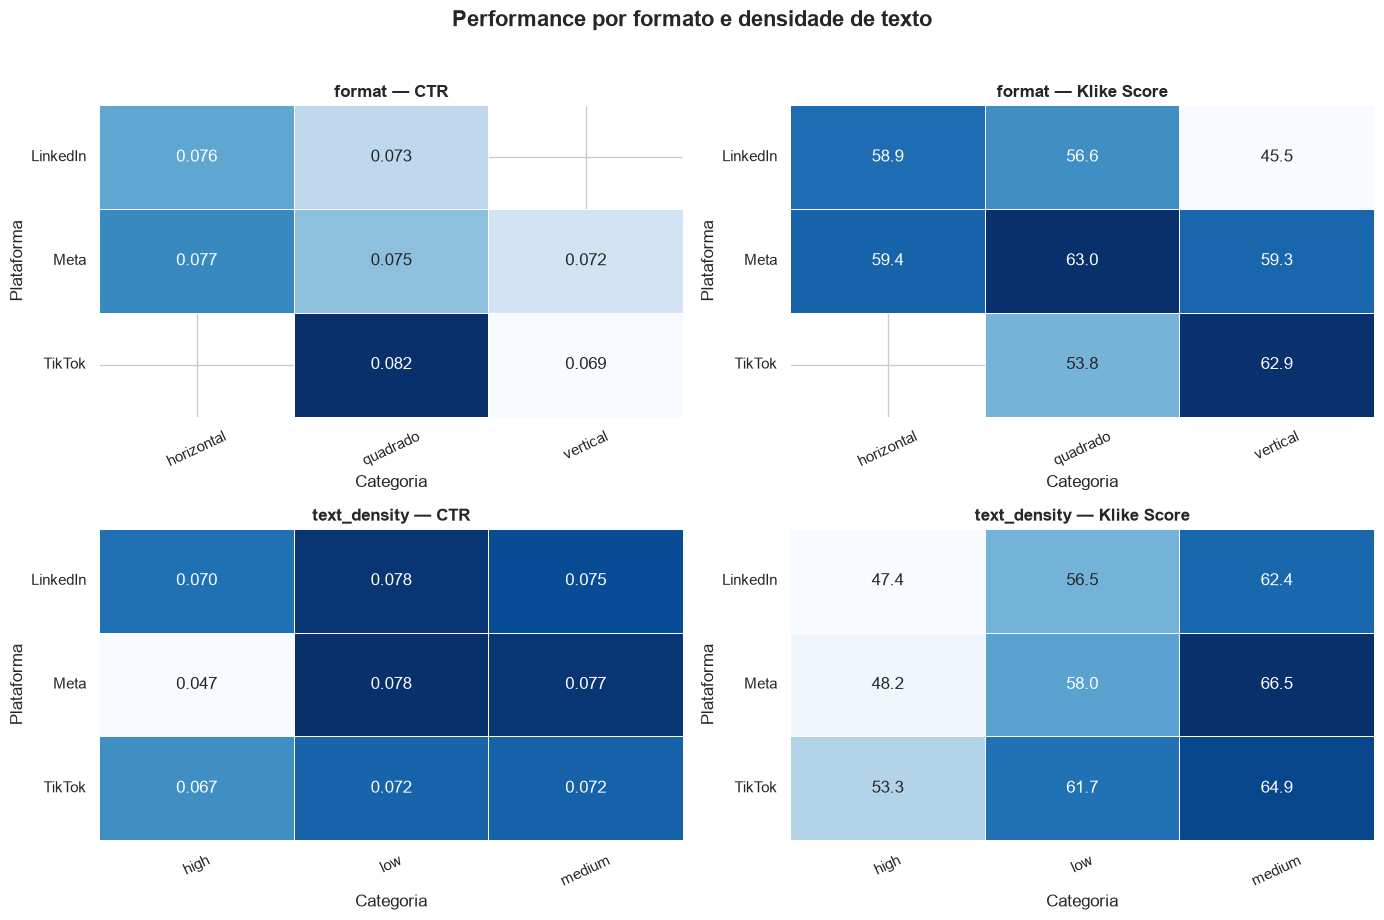

In [35]:

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

configuracoes = [
    ("format", "ctr_medio", "n_ctr", "CTR"),
    ("format", "score_medio", "n_score", "Klike Score"),
    ("text_density", "ctr_medio", "n_ctr", "CTR"),
    ("text_density", "score_medio", "n_score", "Klike Score")
]

for ax, (atributo, metrica, contagem, titulo) in zip(
    axes.flat, configuracoes
):

    dados = comparacao_categoricos[
        comparacao_categoricos["Atributo"] == atributo
    ].copy()

    dados.loc[dados[contagem] < 10, metrica] = np.nan

    matriz = dados.pivot(
        index="platform",
        columns="Categoria",
        values=metrica
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt=".3f" if titulo == "CTR" else ".1f",
        cmap="Blues",
        mask=matriz.isna(),
        linewidths=0.5,
        linecolor="white",
        cbar=False,
        ax=ax
    )

    ax.set_title(
        f"{atributo} — {titulo}",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Categoria")
    ax.set_ylabel("Plataforma")
    ax.tick_params(axis="x", rotation=25)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Performance por formato e densidade de texto",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()



### 5.13. Insights sobre música/voz, formato e densidade de texto

As análises revelaram diferenças na relevância dos atributos criativos:

**Proporção música/voz**

As correlações de Spearman apresentaram magnitudes baixas em todas as plataformas, tanto para CTR quanto para Klike Score. Não foram identificadas evidências de uma associação monotônica forte, o que limita a formulação de recomendações baseadas exclusivamente nessa variável.

**Formato do vídeo**

O desempenho apresentou diferenças por plataforma e por métrica. No TikTok, vídeos quadrados apresentaram CTR médio superior aos verticais (8,17% contra 6,94%), mas os verticais tiveram maior Klike Score médio (62,88 contra 53,80).

Esses resultados indicam que a escolha do formato deve considerar a métrica de interesse e a composição dos grupos analisados.

**Densidade de texto**

A densidade média apresentou o maior Klike Score nas três plataformas:

- LinkedIn: 62,42.
- Meta: 66,52.
- TikTok: 64,91.

A densidade alta apresentou os menores scores em todas as plataformas, sugerindo que o excesso de texto na tela pode estar associado a avaliações inferiores de qualidade.

**Síntese:** entre as variáveis analisadas, a densidade de texto apresentou um padrão mais consistente para o Klike Score, enquanto formato e proporção música/voz exigem maior contextualização.

Esses resultados serão considerados na construção do sistema de recomendações, respeitando as limitações de uma análise observacional.



---

## 6. Análise de correlações

A análise de correlações busca identificar relações entre variáveis numéricas e métricas de desempenho das campanhas.

Será utilizado o coeficiente de Spearman, adequado para investigar associações monotônicas sem exigir linearidade ou normalidade das distribuições.

A análise será dividida em duas perspectivas:

1. **Características e métricas operacionais:** relações com CTR, ROAS, engajamento e Klike Score.
2. **Interpretação de negócio:** identificação das associações mais relevantes para a modelagem e o Recommendations Engine.

As variáveis serão selecionadas para evitar uma matriz excessivamente extensa. Correlações envolvendo métricas matematicamente relacionadas serão interpretadas com cautela.

Vale destacar que correlação não implica causalidade e que as associações observadas podem ser influenciadas por características não controladas das campanhas.


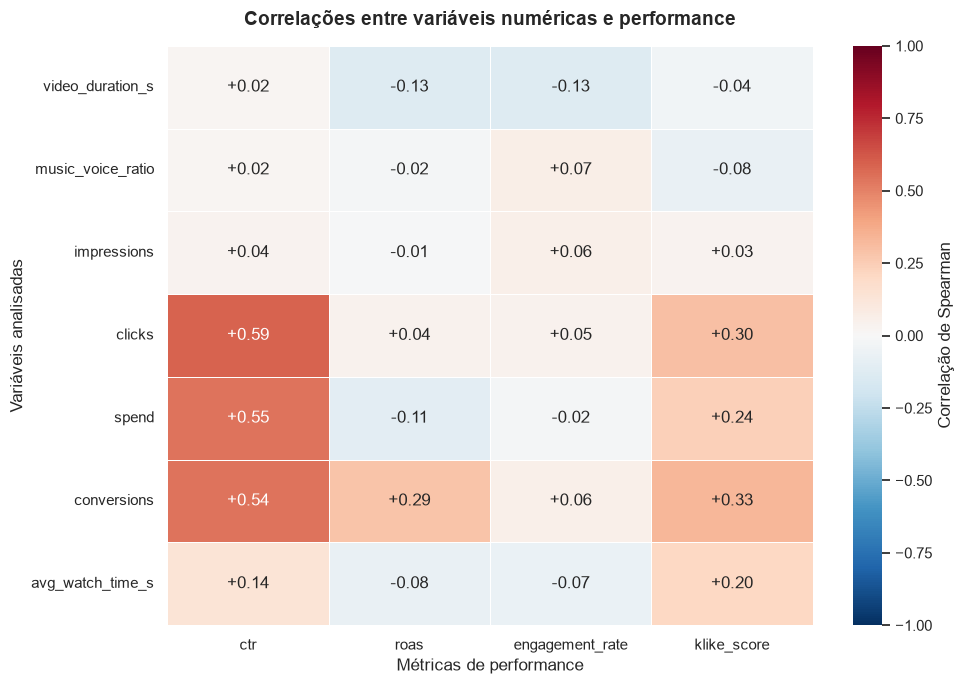

In [36]:

# Variáveis explicativas numéricas
variaveis_explicativas = [
    "video_duration_s",
    "music_voice_ratio",
    "impressions",
    "clicks",
    "spend",
    "conversions",
    "avg_watch_time_s"
]

# Métricas de desempenho
metricas_alvo = [
    "ctr",
    "roas",
    "engagement_rate",
    "klike_score"
]

# Calcular correlações por pares disponíveis
correlacoes = (
    df_performance[
        variaveis_explicativas + metricas_alvo
    ]
    .corr(method="spearman")
    .loc[variaveis_explicativas, metricas_alvo]
)

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    correlacoes,
    annot=True,
    fmt="+.2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlação de Spearman"},
    ax=ax
)

ax.set_title(
    "Correlações entre variáveis numéricas e performance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Métricas de performance")
ax.set_ylabel("Variáveis analisadas")

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()



### 6.1. Interpretação das correlações

A matriz de Spearman revelou diferentes níveis de associação entre variáveis numéricas e métricas de desempenho.

**Principais resultados:**

- **CTR:** apresentou correlações positivas com cliques (ρ = 0,59), investimento (ρ = 0,55) e conversões (ρ = 0,54). Essas relações devem ser interpretadas com cautela devido às dependências entre métricas operacionais.
- **Klike Score:** apresentou as maiores correlações positivas com conversões (ρ = 0,33), cliques (ρ = 0,30) e investimento (ρ = 0,24).
- **ROAS:** apresentou associações relativamente baixas com as variáveis analisadas, sendo conversões a maior correlação positiva (ρ = 0,29).
- **Características do vídeo:** duração e proporção música/voz apresentaram correlações globais próximas de zero com CTR e Klike Score.

Os resultados indicam que as relações entre características dos criativos e desempenho não são inteiramente capturadas por correlações numéricas individuais.

As análises segmentadas e as comparações entre atributos categóricos forneceram informações complementares mais diretamente relacionadas às possíveis melhorias dos vídeos.

**Implicação para o projeto:** a modelagem deverá considerar conjuntamente diferentes características dos criativos, enquanto o Recommendations Engine deverá priorizar atributos modificáveis, como hook, CTA, formato e densidade de texto.



---

## 7. Conclusões da Análise Exploratória

A análise exploratória permitiu compreender a qualidade, a distribuição e as principais associações entre os atributos dos criativos e o desempenho das campanhas.

### 7.1. Qualidade dos dados

O dataset contém 500 campanhas e 26 variáveis, apresentando 235 valores ausentes (1,81% das células).

A análise não identificou padrões fortes de ausência associados às características investigadas, tornando MCAR uma hipótese plausível, embora não comprovada.

Foram identificadas divergências matemáticas em algumas métricas, principalmente no CTR (59 registros). Para preservar a confiabilidade das comparações, os valores inconsistentes foram desconsiderados nas análises específicas de cada métrica, mantendo os dados originais intactos.

### 7.2. Principais descobertas

**1. A presença de hook apresentou associação positiva consistente com performance.**

Campanhas com hook apresentaram CTR médio 38,66% superior e Klike Score médio 33,33% maior na análise agregada.

A associação positiva também foi observada nas três plataformas, tornando o hook um atributo promissor para futuras recomendações.

**2. Rostos humanos apresentaram associação positiva com engajamento.**

Campanhas com rostos humanos apresentaram taxa média de engajamento 38,21% superior, destacando-se como uma característica relevante para investigar estratégias de retenção e interação.

**3. O desempenho dos criativos variou entre plataformas.**

No Meta, vídeos de até 15 segundos apresentaram o maior CTR médio (8,18%). No TikTok, a faixa de 16 a 30 segundos apresentou o maior resultado (8,62%).

Essas diferenças sugerem que as recomendações devem considerar o contexto de cada plataforma.

**4. A densidade de texto apresentou um padrão consistente para o Klike Score.**

A densidade média apresentou o maior Klike Score nas três plataformas, enquanto a densidade alta apresentou os menores resultados.

Esse padrão sugere que reduzir a quantidade excessiva de texto na tela pode representar uma oportunidade de otimização.

**5. Nem todas as características apresentaram associações relevantes.**

A proporção música/voz apresentou correlações baixas com CTR e Klike Score, indicando que sua utilização isolada como critério de recomendação não é sustentada pelas evidências encontradas.

### 7.3. Limitações

Os resultados representam associações observacionais e não permitem estabelecer causalidade.

Além disso, devem ser consideradas algumas limitações:

- Dataset simulado e relativamente pequeno, com 500 campanhas.
- Valores ausentes e divergências em métricas de performance.
- Diferenças no tamanho dos grupos analisados.
- Possíveis influências de variáveis como objetivo da campanha, público-alvo e categoria do anunciante.
- Comparações descritivas sem controle simultâneo de todos os fatores relevantes.

### 7.4. Implicações para as próximas etapas

Os resultados exploratórios fornecem direcionamentos para a modelagem preditiva e o desenvolvimento do Recommendations Engine.

Na modelagem, serão investigadas as contribuições conjuntas dos atributos para a previsão do `klike_score`, considerando técnicas adequadas de pré-processamento e validação.

No sistema de recomendações, serão priorizadas características modificáveis dos criativos, com sugestões contextualizadas por plataforma e estimativas de melhoria fundamentadas nos padrões observados.

**Conclusão:** a análise sugere que elementos de atenção, presença humana, duração e densidade de texto são candidatos relevantes para a otimização dos criativos, mas seu potencial deve ser avaliado considerando o contexto das campanhas e as limitações dos dados.
